**BANK LOAN ANALYSIS**

**IMPORT THE REQUIRED LIBRARIES**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly.express as px

In [4]:
df=pd.read_excel('/content/financial_loan_data_excel.xlsx')

In [5]:
df.head(5)

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


METADATA OF **DATA**

In [6]:
df.shape[0] #Number of Rows

38576

In [7]:
df.shape[1] #Number of Columns

24

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     38576 non-null  int64         
 1   address_state          38576 non-null  object        
 2   application_type       38576 non-null  object        
 3   emp_length             38576 non-null  object        
 4   emp_title              37138 non-null  object        
 5   grade                  38576 non-null  object        
 6   home_ownership         38576 non-null  object        
 7   issue_date             38576 non-null  datetime64[ns]
 8   last_credit_pull_date  38576 non-null  datetime64[ns]
 9   last_payment_date      38576 non-null  datetime64[ns]
 10  loan_status            38576 non-null  object        
 11  next_payment_date      38576 non-null  datetime64[ns]
 12  member_id              38576 non-null  int64         
 13  p

**DATATYPES**

In [9]:
df.dtypes

,0
id,int64
address_state,object
application_type,object
emp_length,object
emp_title,object
grade,object
home_ownership,object
issue_date,datetime64[ns]
last_credit_pull_date,datetime64[ns]
last_payment_date,datetime64[ns]


In [10]:
df.describe()

,id,issue_date,last_credit_pull_date,last_payment_date,next_payment_date,member_id,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
count,3.857600e+04,38576,38576,38576,38576,3.857600e+04,3.857600e+04,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000
mean,6.810371e+05,2021-07-16 02:31:35.562007040,2021-06-08 13:36:34.193280512,2021-06-26 09:52:08.909166080,2021-07-26 20:42:20.605557760,8.476515e+05,6.964454e+04,0.133274,326.862965,0.120488,11296.066855,22.132544,12263.348533
min,5.473400e+04,2021-01-01 00:00:00,2021-01-08 00:00:00,2021-01-08 00:00:00,2021-02-08 00:00:00,7.069900e+04,4.000000e+03,0.000000,15.690000,0.054200,500.000000,2.000000,34.000000
25%,5.135170e+05,2021-04-11 00:00:00,2021-04-15 00:00:00,2021-03-16 00:00:00,2021-04-16 00:00:00,6.629788e+05,4.150000e+04,0.082100,168.450000,0.093200,5500.000000,14.000000,5633.000000
50%,6.627280e+05,2021-07-11 00:00:00,2021-05-16 00:00:00,2021-06-14 00:00:00,2021-07-14 00:00:00,8.473565e+05,6.000000e+04,0.134200,283.045000,0.118600,10000.000000,20.000000,10042.000000
75%,8.365060e+05,2021-10-11 00:00:00,2021-08-13 00:00:00,2021-09-15 00:00:00,2021-10-15 00:00:00,1.045652e+06,8.320050e+04,0.185900,434.442500,0.145900,15000.000000,29.000000,16658.000000
max,1.077501e+06,2021-12-12 00:00:00,2022-01-20 00:00:00,2021-12-15 00:00:00,2022-01-15 00:00:00,1.314167e+06,6.000000e+06,0.299900,1305.190000,0.245900,35000.000000,90.000000,58564.000000
std,2.113246e+05,NaN,NaN,NaN,NaN,2.668105e+05,6.429368e+04,0.066662,209.092000,0.037164,7460.746022,11.392282,9051.104777


TOTAL LOAN **APPLICATIONS**

In [11]:
total_loan_application=df['id'].count()
print("Total Loan Applications:",total_loan_application)

Total Loan Applications: 38576


**MTD TOTAL LOAN APPLICATIONS**

In [12]:
latest_issue_date=df['issue_date'].max()
latest_year=latest_issue_date.year
latest_month=latest_issue_date.month
mtd_data=df[(df['issue_date'].dt.year==latest_year) & (df['issue_date'].dt.month==latest_month)]
mtd_loan_applications=mtd_data['id'].count()
print(f"MTD Total Loan Applications (for {latest_issue_date.strftime('%B %Y')}): {mtd_loan_applications}")

MTD Total Loan Applications (for December 2021): 4314


**TOTAL FUNDED AMOUNT**

In [13]:
total_funded_amount=df['loan_amount'].sum()
total_funded_amount_millions=total_funded_amount/1000000
print("Total Funded Amount:${:.2f}M".format(total_funded_amount_millions))

Total Funded Amount:$435.76M


**MTD TOTAL FUNDED AMOUNT**

In [14]:
latest_issue_date=df['issue_date'].max()
latest_year=latest_issue_date.year
latest_month=latest_issue_date.month
mtd_data=df[(df['issue_date'].dt.year==latest_year) & (df['issue_date'].dt.month==latest_month)]
mtd_total_funded_amount=mtd_data['loan_amount'].sum()
mtd_total_funded_amount_millions=mtd_total_funded_amount/1000000
print("MTD Total Funded Amount:${:.2f}M".format(mtd_total_funded_amount_millions))

MTD Total Funded Amount:$53.98M


**TOTAL AMOUNT RECEIVED**

In [15]:
total_amount_received=df['total_payment'].sum()
total_amount_received_millions=total_amount_received/1000000
print("Total Funded Amount:${:.2f}M".format(total_amount_received_millions))

Total Funded Amount:$473.07M


**MTD TOTAL AMOUNT RECEIVED**

In [16]:
latest_issue_date=df['issue_date'].max()
latest_year=latest_issue_date.year
latest_month=latest_issue_date.month
mtd_data=df[(df['issue_date'].dt.year==latest_year) & (df['issue_date'].dt.month==latest_month)]
mtd_total_amount_received=mtd_data['total_payment'].sum()
mtd_total_amount_received_millions=mtd_total_amount_received/1000000
print("MTD Total Amount Received:${:.2f}M".format(mtd_total_amount_received_millions))

MTD Total Amount Received:$58.07M


**AVERAGE INTEREST RATE**

In [17]:
average_interest_rate=df['int_rate'].mean()*100
print("Avg Int Rate: {:.2f}%".format(average_interest_rate))

Avg Int Rate: 12.05%


**AVERAGE DEBT-TO-INCOME-RATIO (DTI)**

In [18]:
average_dti=df['dti'].mean()*100
print("Avg DTI: {:.2f}%".format(average_dti))

Avg DTI: 13.33%


**GOOD LOAN METRICS**

In [19]:
good_loans=df[df['loan_status'] .isin (["Fully Paid","Current"])]
total_loan_applications=df['id'].count()
good_loan_applications=good_loans['id'].count()
good_loan_funded_amount=good_loans['loan_amount'].sum()
good_loan_received=good_loans['total_payment'].sum()
good_loan_funded_amount_millions=good_loan_funded_amount/1000000
good_loan_received_millions=good_loan_received/1000000
good_loan_percentage=(good_loan_applications/total_loan_applications)*100
print("Good Loan Applications:",good_loan_applications)
print("Good Loan Funded Amount (in Millions):${:.2f}M".format(good_loan_funded_amount_millions))
print("Good Loan Total Received:${:.2f}M".format(good_loan_received_millions))
print("Percentage of Good Loan Applications: {:.2f}%".format(good_loan_percentage))

Good Loan Applications: 33243
Good Loan Funded Amount (in Millions):$370.22M
Good Loan Total Received:$435.79M
Percentage of Good Loan Applications: 86.18%


**Bad Loan Metrics**

In [20]:
bad_loans=df[df['loan_status'] .isin (["Charged Off"])]
total_loan_applications=df['id'].count()
bad_loan_applications=bad_loans['id'].count()
bad_loan_funded_amount=bad_loans['loan_amount'].sum()
bad_loan_received=bad_loans['total_payment'].sum()
bad_loan_funded_amount_millions=bad_loan_funded_amount/1000000
bad_loan_received_millions=bad_loan_received/1000000
bad_loan_percentage=(bad_loan_applications/total_loan_applications)*100
print("Bad Loan Applications:",bad_loan_applications)
print("Bad Loan Funded Amount (in Millions):${:.2f}M".format(bad_loan_funded_amount_millions))
print("Bad Loan Total Received:${:.2f}M".format(bad_loan_received_millions))
print("Percentage of Bad Loan Applications: {:.2f}%".format(bad_loan_percentage))

Bad Loan Applications: 5333
Bad Loan Funded Amount (in Millions):$65.53M
Bad Loan Total Received:$37.28M
Percentage of Bad Loan Applications: 13.82%


**MONTHLY TRENDS BY ISSUE DATE FOR TOTAL FUNDED AMOUNT**

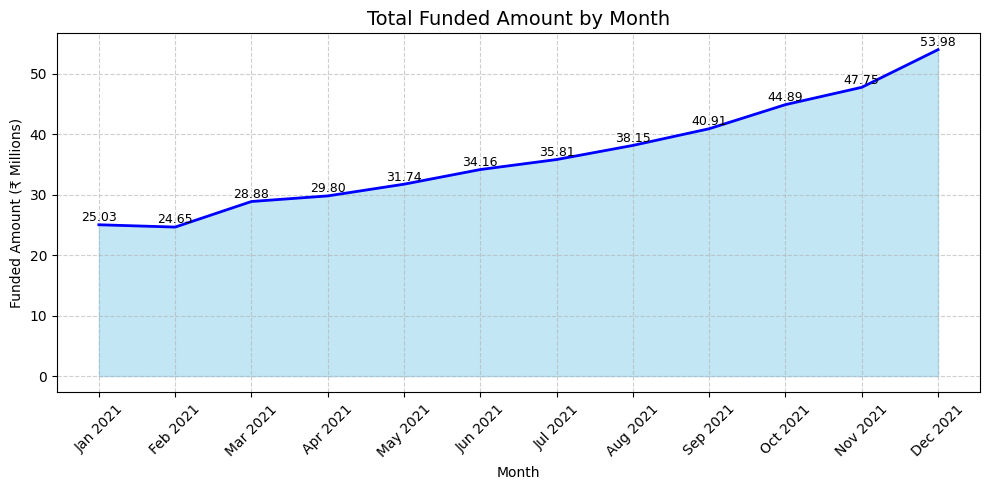

In [21]:

monthly_funded = (
    df.sort_values('issue_date')
      .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
      .groupby('month_name', sort=False)['loan_amount']
      .sum()
      .div(1_000_000)
      .reset_index(name='loan_amount_millions')
)

plt.figure(figsize=(10, 5))
plt.fill_between(monthly_funded['month_name'], monthly_funded['loan_amount_millions'], color='skyblue', alpha=0.5)
plt.plot(monthly_funded['month_name'], monthly_funded['loan_amount_millions'], color='blue', linewidth=2)

for i, row in monthly_funded.iterrows():
    plt.text(i, row['loan_amount_millions'] + 0.1, f"{row['loan_amount_millions']:.2f}",
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

plt.title('Total Funded Amount by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Funded Amount (₹ Millions)')
plt.xticks(ticks=range(len(monthly_funded)), labels=monthly_funded['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


**MONTHLY TRENDS BY ISSUE DATE FOR TOTAL AMOUNT RECEIVED**

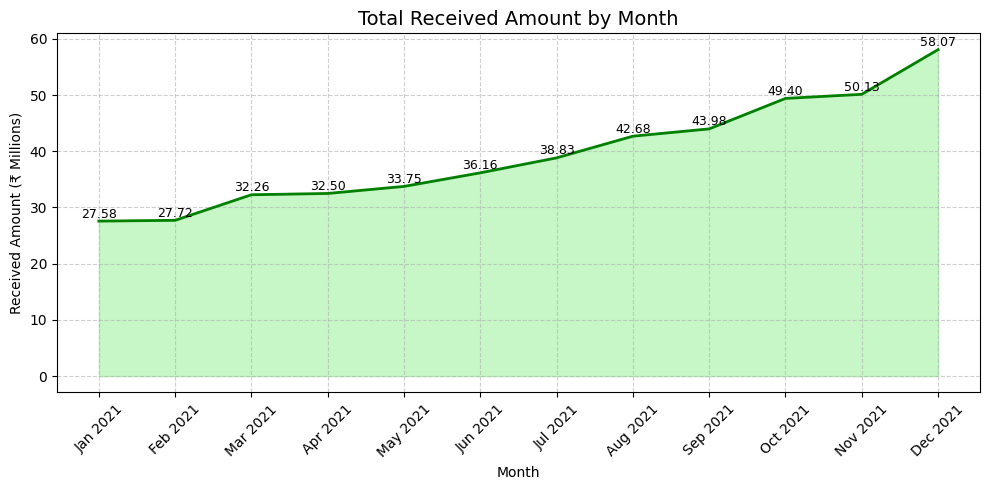

In [22]:


monthly_received = (
    df.sort_values('issue_date')
    .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
    .groupby('month_name', sort=False)['total_payment']
    .sum()
    .div(1_000_000)
    .reset_index(name='received_amount_millions')
)

plt.figure(figsize=(10, 5))
plt.fill_between(monthly_received['month_name'], monthly_received['received_amount_millions'],
                 color='lightgreen', alpha=0.5)
plt.plot(monthly_received['month_name'], monthly_received['received_amount_millions'],
         color='green', linewidth=2)

for i, row in monthly_received.iterrows():
    plt.text(i, row['received_amount_millions'] + 0.1, f"{row['received_amount_millions']:.2f}",
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

plt.title('Total Received Amount by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Received Amount (₹ Millions)')
plt.xticks(ticks=range(len(monthly_received)), labels=monthly_received['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**MONTHLY TRENDS BY ISSUE DATE FOR TOTAL LOAN APPLICATIONS**

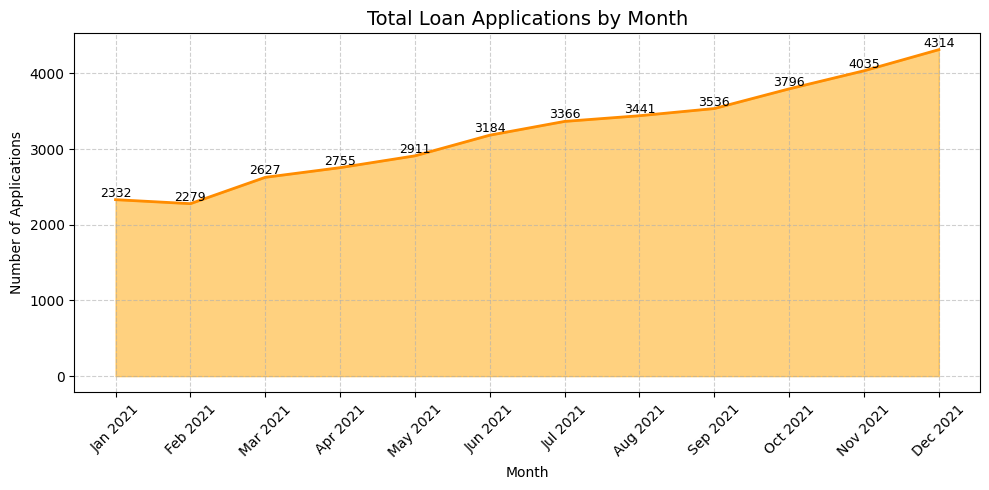

In [23]:


monthly_applications = (
    df.sort_values('issue_date')
    .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
    .groupby('month_name', sort=False)['id']
    .count()
    .reset_index(name='loan_applications_count')
)

plt.figure(figsize=(10, 5))
plt.fill_between(monthly_applications['month_name'], monthly_applications['loan_applications_count'],
                 color='orange', alpha=0.5)
plt.plot(monthly_applications['month_name'], monthly_applications['loan_applications_count'],
         color='darkorange', linewidth=2)

for i, row in monthly_applications.iterrows():
    plt.text(i, row['loan_applications_count'] + 0.5, f"{row['loan_applications_count']}",
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

plt.title('Total Loan Applications by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.xticks(ticks=range(len(monthly_applications)), labels=monthly_applications['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

REGIONAL ANALYSIS BY STATE FOR TOTAL FUNDED AMOUNT

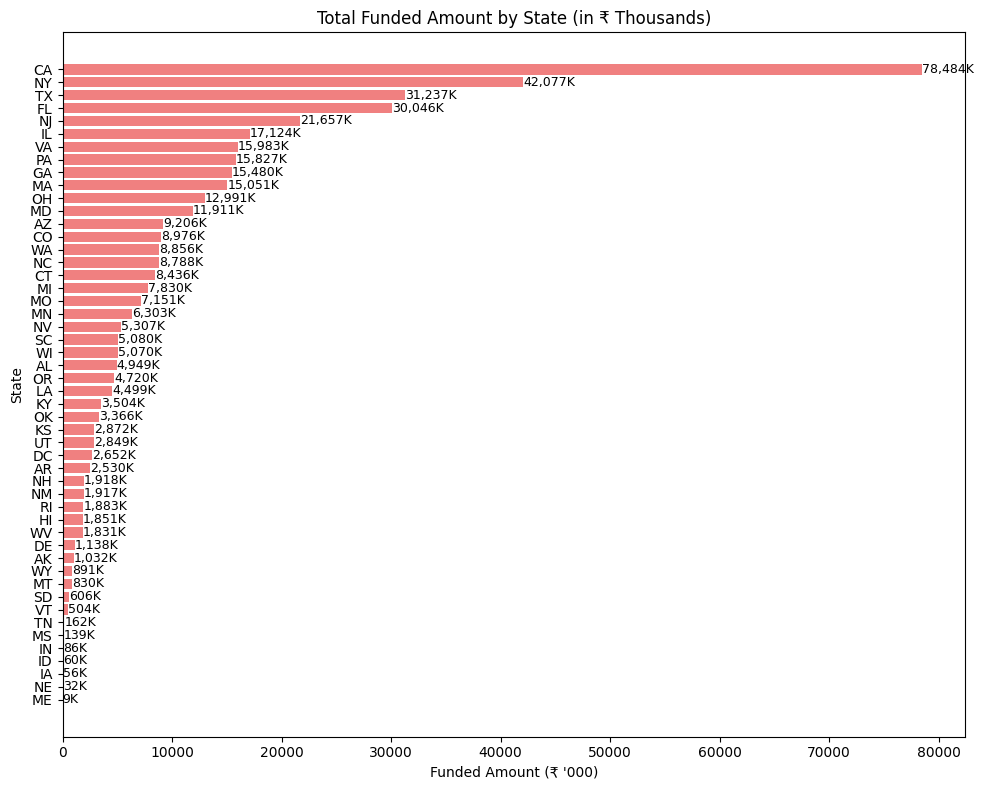

In [24]:


state_funding = df.groupby('address_state')['loan_amount'].sum().sort_values(ascending=True)
state_funding_thousands = state_funding / 1000

plt.figure(figsize=(10, 8))
bars = plt.barh(state_funding_thousands.index, state_funding_thousands.values, color='lightcoral')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height() / 2,
             f'{width:,.0f}K', va='center', fontsize=9)

plt.title('Total Funded Amount by State (in ₹ Thousands)')
plt.xlabel('Funded Amount (₹ \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

**REGIONAL ANALYSIS BY STATE FOR TOTAL AMOUNT RECEIVED**

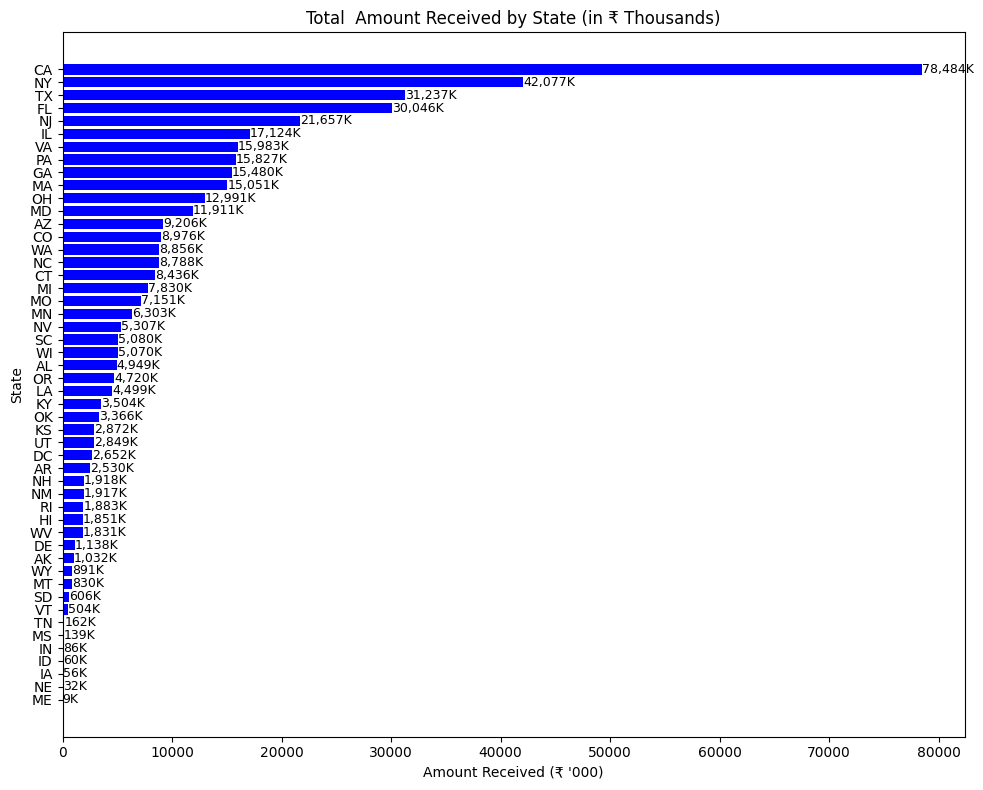

In [25]:
state_amount_received = df.groupby('address_state')['total_payment'].sum().sort_values(ascending=True)
state_amount_received_thousands = state_funding / 1000

plt.figure(figsize=(10, 8))
bars = plt.barh(state_amount_received_thousands.index, state_amount_received_thousands.values, color='blue')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height() / 2,
             f'{width:,.0f}K', va='center', fontsize=9)

plt.title('Total  Amount Received by State (in ₹ Thousands)')
plt.xlabel('Amount Received (₹ \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

**REGIONAL ANALYSIS BY STATE FOR TOTAL LOAN APPLICATIONS**

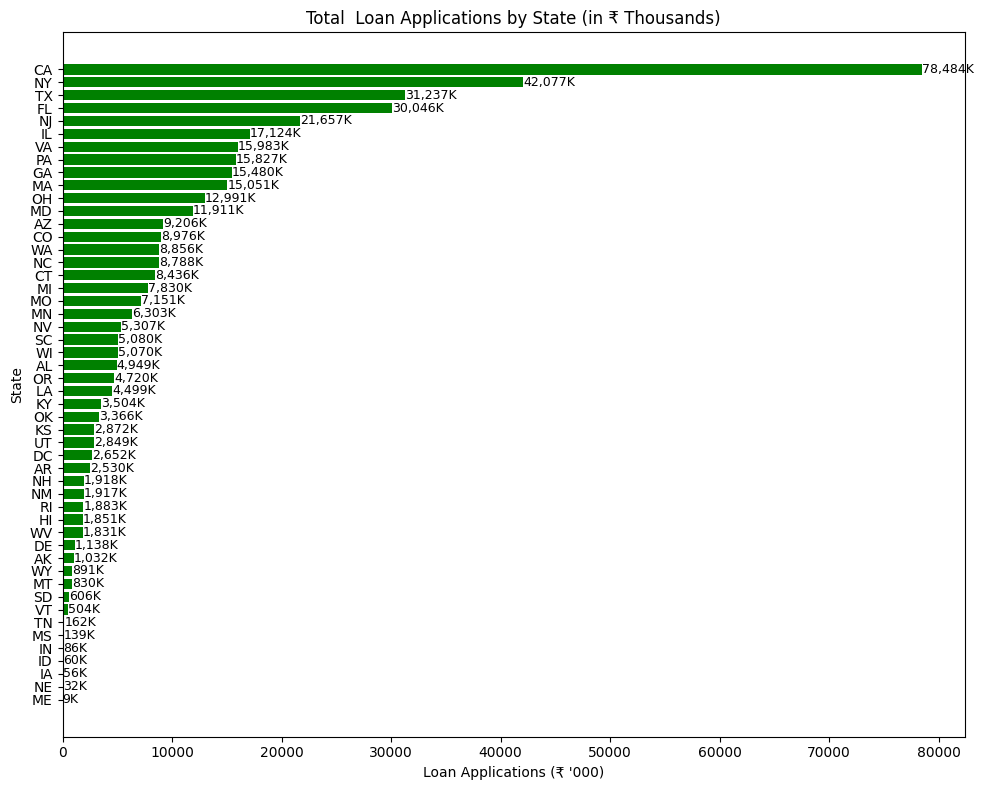

In [26]:
state_loan_applications_received = df.groupby('address_state')['id'].count().sort_values(ascending=True)
state_loan_applications_received_thousands = state_funding / 1000

plt.figure(figsize=(10, 8))
bars = plt.barh(state_loan_applications_received_thousands.index, state_loan_applications_received_thousands.values, color='green')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height() / 2,
             f'{width:,.0f}K', va='center', fontsize=9)

plt.title('Total  Loan Applications by State (in ₹ Thousands)')
plt.xlabel('Loan Applications (₹ \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

**LOAN TERM ANALYSIS BY TOTAL FUNDED AMOUNT**

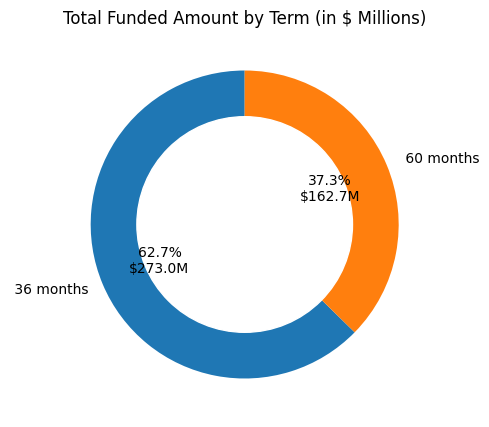

In [27]:


term_funding_millions = df.groupby('term')['loan_amount'].sum() / 1000000

plt.figure(figsize=(5, 5))
plt.pie(
    term_funding_millions,
    labels=term_funding_millions.index,
    autopct=lambda p: f"{p:.1f}%\n${p*sum(term_funding_millions)/100:.1f}M",
    startangle=90,
    wedgeprops={'width': 0.4}
)
plt.gca().add_artist(plt.Circle((0, 0), 0.70, color='white'))
plt.title("Total Funded Amount by Term (in $ Millions)")
plt.show()

**LOAN TERM ANALYSIS BY TOTAL AMOUNT RECEIVED**

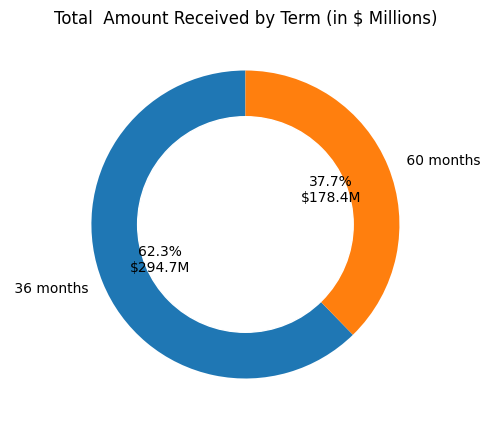

In [28]:
term_amount_received_millions = df.groupby('term')['total_payment'].sum() / 1000000

plt.figure(figsize=(5, 5))
plt.pie(
    term_amount_received_millions,
    labels=term_amount_received_millions.index,
    autopct=lambda p: f"{p:.1f}%\n${p*sum(term_amount_received_millions)/100:.1f}M",
    startangle=90,
    wedgeprops={'width': 0.4}
)
plt.gca().add_artist(plt.Circle((0, 0), 0.70, color='white'))
plt.title("Total  Amount Received by Term (in $ Millions)")
plt.show()

**LOAN TERM ANALYSIS BY TOTAL LOAN APPLICATIONS**

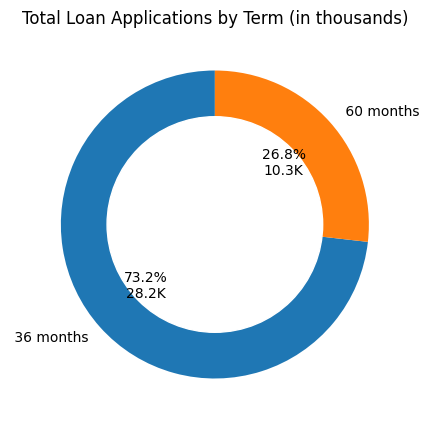

In [29]:
term_loan_applications_thousands = df.groupby('term')['id'].count() / 1000

plt.figure(figsize=(5, 5))
plt.pie(
    term_loan_applications_thousands,
    labels=term_loan_applications_thousands.index,
    autopct=lambda p: f"{p:.1f}%\n{p*sum(term_loan_applications_thousands)/100:.1f}K",
    startangle=90,
    wedgeprops={'width': 0.4}
)
plt.gca().add_artist(plt.Circle((0, 0), 0.70, color='white'))
plt.title("Total Loan Applications by Term (in thousands)")
plt.show()

**EMPLOYEE LENGTH BY TOTAL FUNDED AMOUNT**

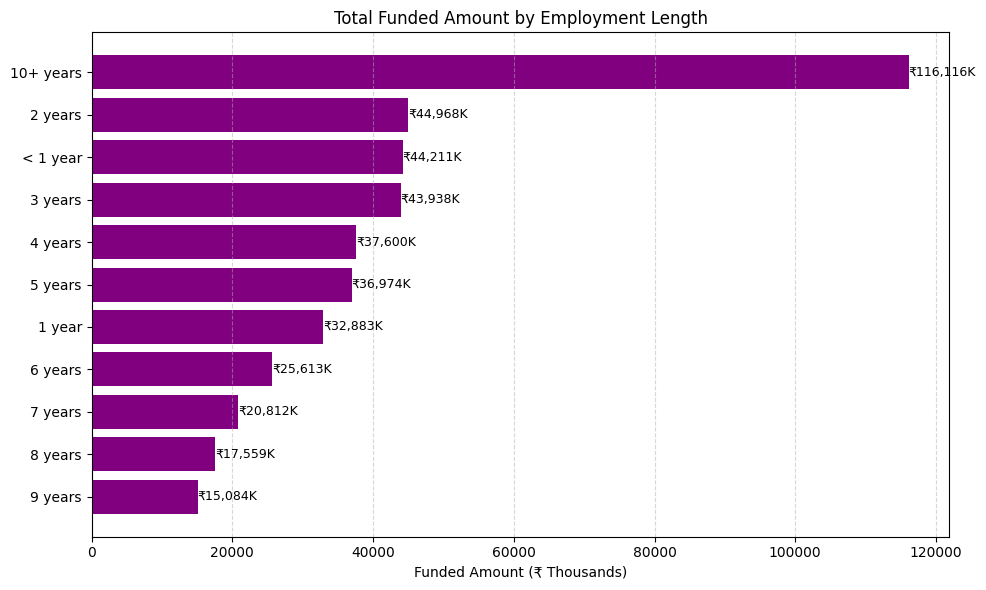

In [30]:


emp_funding_thousands = df.groupby('emp_length')['loan_amount'].sum().sort_values() / 1000

plt.figure(figsize=(10, 6))
bars = plt.barh(emp_funding_thousands.index, emp_funding_thousands, color='purple')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2,
             f"₹{width:,.0f}K", va='center', fontsize=9)

plt.xlabel("Funded Amount (₹ Thousands)")
plt.title("Total Funded Amount by Employment Length")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**EMPLOYEE LENGTH BY TOTAL AMOUNT RECEIVED**

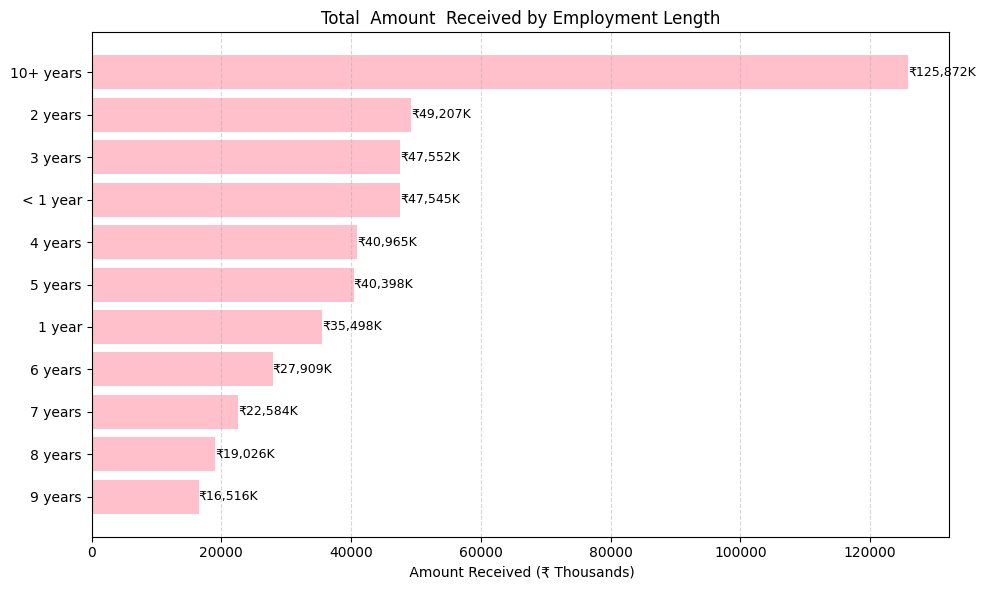

In [31]:
emp_amount_received_thousands = df.groupby('emp_length')['total_payment'].sum().sort_values() / 1000

plt.figure(figsize=(10, 6))
bars = plt.barh(emp_amount_received_thousands.index, emp_amount_received_thousands, color='pink')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2,
             f"₹{width:,.0f}K", va='center', fontsize=9)

plt.xlabel(" Amount Received (₹ Thousands)")
plt.title("Total  Amount  Received by Employment Length")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**EMPLOYEE LENGTH BY TOTAL LOAN APPLICATIONS**

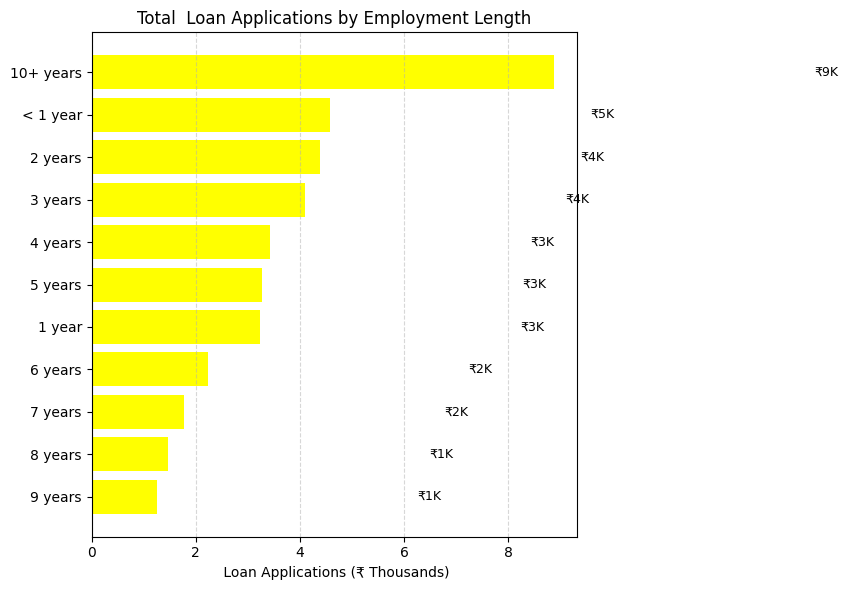

In [32]:
emp_loan_applications_thousands = df.groupby('emp_length')['id'].count().sort_values() / 1000

plt.figure(figsize=(10, 6))
bars = plt.barh(emp_loan_applications_thousands.index, emp_loan_applications_thousands, color='yellow')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2,
             f"₹{width:,.0f}K", va='center', fontsize=9)

plt.xlabel(" Loan Applications (₹ Thousands)")
plt.title("Total  Loan Applications by Employment Length")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**LOAN PURPOSE BY TOTAL FUNDED AMOUNT**

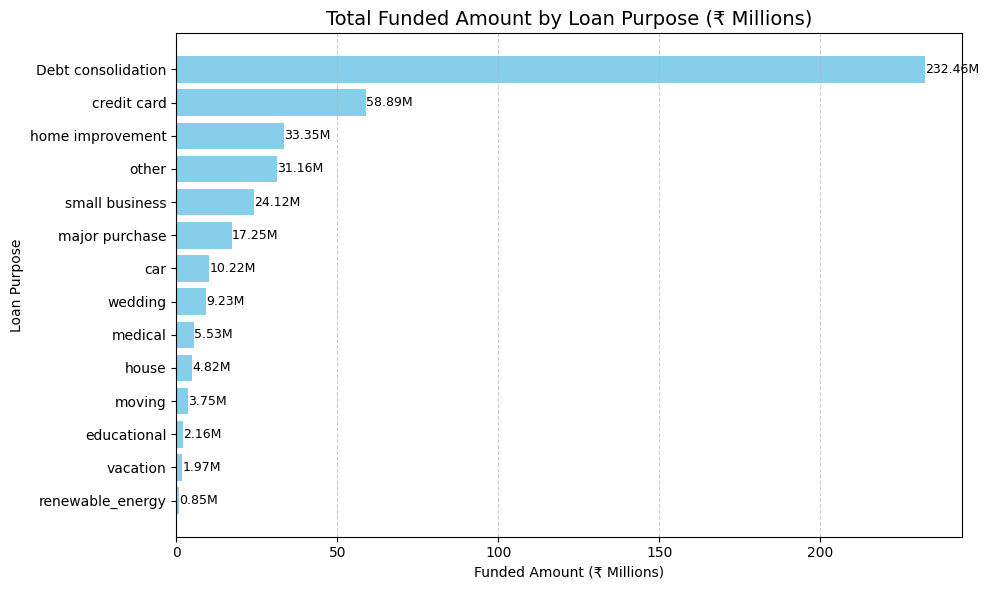

In [33]:
purpose_funding_millions = (df.groupby('purpose')['loan_amount'].sum().sort_values()/ 1000000)

plt.figure(figsize=(10, 6))
bars = plt.barh(purpose_funding_millions.index, purpose_funding_millions.values, color='skyblue')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}M', va='center', fontsize=9)

plt.title('Total Funded Amount by Loan Purpose (₹ Millions)', fontsize=14)
plt.xlabel('Funded Amount (₹ Millions)')
plt.ylabel('Loan Purpose')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**LOAN PURPOSE BY TOTAL AMOUNT RECEIVED**

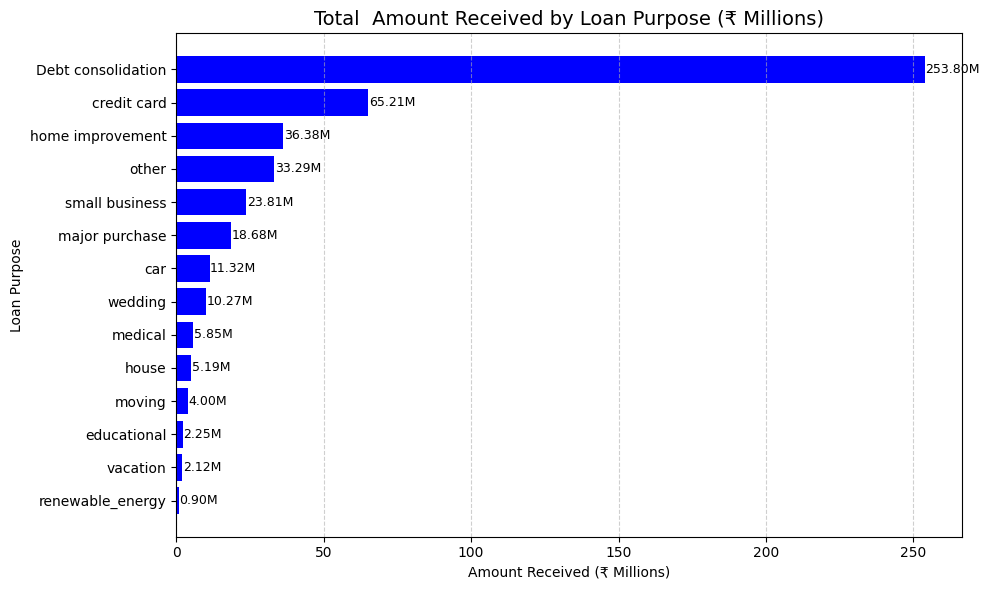

In [34]:
purpose_amount_received_millions = (df.groupby('purpose')['total_payment'].sum().sort_values()/ 1000000)

plt.figure(figsize=(10, 6))
bars = plt.barh(purpose_amount_received_millions.index, purpose_amount_received_millions.values, color='blue')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}M', va='center', fontsize=9)

plt.title('Total  Amount Received by Loan Purpose (₹ Millions)', fontsize=14)
plt.xlabel('Amount Received (₹ Millions)')
plt.ylabel('Loan Purpose')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**LOAN PURPOSE BY TOTAL LOAN APPLICATIONS**

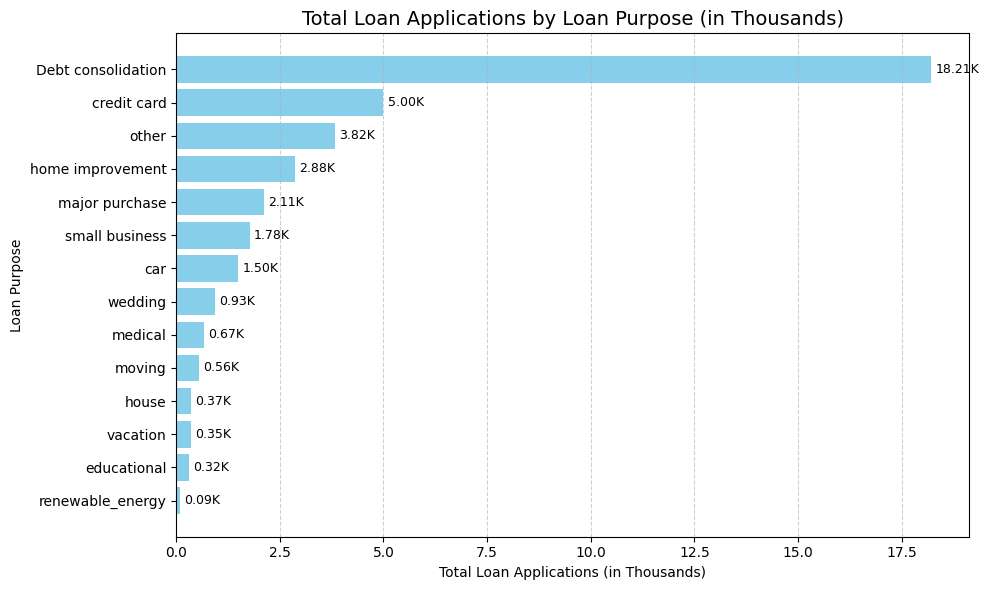

In [35]:
purpose_loan_thousands = (df.groupby('purpose')['id'].count().sort_values() / 1000)

plt.figure(figsize=(10, 6))
bars = plt.barh(purpose_loan_thousands.index, purpose_loan_thousands.values, color='skyblue')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}K', va='center', fontsize=9)

plt.title('Total Loan Applications by Loan Purpose (in Thousands)', fontsize=14)
plt.xlabel('Total Loan Applications (in Thousands)')
plt.ylabel('Loan Purpose')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**HOME OWNERSHIP BY TOTAL FUNDED AMOUNT**

In [36]:
home_funding = df.groupby('home_ownership')['loan_amount'].sum().reset_index()
home_funding['loan_amount_millions'] = home_funding['loan_amount'] / 1_000_000

fig = px.treemap(
    home_funding,
    path=['home_ownership'],
    values='loan_amount_millions',
    color='loan_amount_millions',
    color_continuous_scale='Blues',
    title='Total Funded Amount by Home Ownership (₹ Millions)'
)

fig.show()

HOME OWNERSHIP BY TOTAL AMOUNT RECEIVED

In [37]:
home_amount_received = df.groupby('home_ownership')['total_payment'].sum().reset_index()
home_amount_received['total_payment_millions'] = home_amount_received['total_payment'] / 1_000_000

fig = px.treemap(
    home_amount_received,
    path=['home_ownership'],
    values='total_payment_millions',
    color='total_payment_millions',
    color_continuous_scale='Blues',
    title='Total  Amount Received by Home Ownership (₹ Millions)'
)

fig.show()

**HOME OWNERSHIP BY TOTAL LOAN APPLICATIONS**

In [39]:
home_loan_applications = df.groupby('home_ownership')['id'].count().reset_index(name='id_thousands')
home_loan_applications['id_thousands'] = home_loan_applications['id_thousands'] / 1000

fig = px.treemap(
    home_loan_applications,
    path=['home_ownership'],
    values='id_thousands',
    color='id_thousands',
    color_continuous_scale='Blues',
    title='Total Loan Applications (₹ Thousands)'
)

fig.show()